# SVHN 이미지 다중분류 실습문제

실제 거리 사진에서 숫자 이미지를 입력받아 0부터 9까지 10개의 숫자 중 하나로 분류하는 CNN(합성곱 신경망)을 구현하시오.

- 데이터셋: SVHN (Street View House Numbers)
- 학습 데이터: 73,257개
- 테스트 데이터: 26,032개
- 추가 데이터: 531,131개 (이번 실습에서는 사용하지 않음)
- 이미지 크기: 32 × 32


| 구분 | 내용 |
|---|---|
| 데이터 | SVHN |
| 입력 데이터 | RGB 이미지 |
| 입력 Shape | `(3, 32, 32)` |
| 출력 데이터 | 10개 클래스 |
| 정답 레이블 | 0~9 |
| 손실함수 | `CrossEntropyLoss` |
| Optimizer | Adam |

#### STEP 1. 라이브러리 불러오기 및 실행 환경 확인

**실습 조건**

| 변수 | 값 |
|---|---:|
| `BATCH_SIZE` | 64 |
| `EPOCH` | 10 |
| `LR` | 0.001 |
| `IMAGE_SIZE` | 32 |

In [14]:
import torch
from torch import nn, optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import scipy.io as sio
import os
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE)

BATCH_SIZE = 64
LR=1e-1
EPOCH=10
IMAGE_SIZE=32

cpu


#### STEP 2. 데이터 다운로드 및 데이터셋 확인

**문제**

1. `torchvision.datasets.SVHN`을 이용하여 학습 데이터를 다운로드하시오.
2. 테스트 데이터를 다운로드하시오.
3. `split="train"`과 `split="test"`를 구분하여 사용하시오.
4. 학습 데이터와 테스트 데이터의 개수를 출력하시오.
5. 이미지와 정답 레이블의 구조를 확인하시오.

**주의** SVHN 데이터셋에서는 숫자 0의 레이블이 10으로 저장되어 있다. 모델에서 사용할 클래스 번호 0~9에 맞도록 변환하여 사용

In [4]:
train_DS=datasets.SVHN(
    root='data',
    split='train',
    download=True,
    target_transform=lambda y:0 if y==10 else y
)
test_DS=datasets.SVHN(
    root='data',
    split='test',
    download=True,
    target_transform=lambda y:0 if y==10 else y
)

print(f'학습 데이터 개수: {len(train_DS)}')
print(f'테스트 데이터 개수: {len(train_DS)}')

img, label= train_DS[0]
print(f'타입: {type(img)}, 크기: {img.size}')
print(f'레이블: {label}, 전체 배열: {train_DS.data.shape}')
print(f'종류: {np.unique(train_DS.labels)}')

100.0%
100.0%


학습 데이터 개수: 73257
테스트 데이터 개수: 73257
타입: <class 'PIL.Image.Image'>, 크기: (32, 32)
레이블: 1, 전체 배열: (73257, 3, 32, 32)
종류: [0 1 2 3 4 5 6 7 8 9]


#### STEP 3. 이미지 전처리 및 DataLoader 생성

**전처리 조건**

- `transforms.Compose()`를 이용하여 이미지 전처리를 구성한다.
- `transforms.ToTensor()`를 적용한다.
- 이미지 픽셀 값은 0~1 범위로 변환한다.
- 이미지 크기는 32 × 32를 유지한다.
- 학습 데이터와 테스트 데이터에 동일한 전처리를 적용한다.
- 학습 데이터 중 20%를 검증 데이터로 분리한다.

**문제**

1. 이미지 전처리를 구성하시오.
2. 학습 데이터와 테스트 데이터에 전처리를 적용하시오.
3. SVHN의 정답 레이블 10을 0으로 변환하시오.
4. 학습 데이터의 20%를 검증 데이터로 분리하시오.
5. 학습·검증·테스트용 `DataLoader`를 생성하시오.
6. 학습 데이터는 `shuffle=True`, 검증 및 테스트 데이터는 `shuffle=False`로 설정하시오.
7. 첫 번째 배치의 이미지와 정답 레이블 shape를 출력하시오.
8. 이미지 9장을 정답 레이블과 함께 시각화하시오.

**주의:** SVHN 데이터셋에는 `classes` 속성이 기본 제공되지 않는다. 숫자 클래스 이름 목록을 준비하여 시각화 및 혼동행렬에 활용하시오.

torch.Size([64, 3, 32, 32]) torch.Size([64])


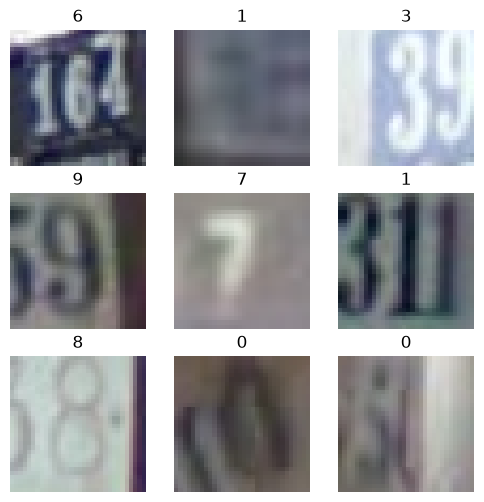

In [5]:
from torch.utils.data import random_split

transform=transforms.Compose([transforms.ToTensor()])

train_DS_full=datasets.SVHN(
    root='data',
    split='train',
    download=True,
    transform=transform,
    target_transform=lambda y:0 if y==10 else y
)
test_DS=datasets.SVHN(
    root='data',
    split='test',
    download=True,
    transform=transform,
    target_transform=lambda y:0 if y==10 else y
)

val_size=int(len(train_DS_full)*0.2)
train_size=len(train_DS_full) - val_size
train_DS, val_DS=random_split(train_DS_full, [train_size, val_size])

train_DL=DataLoader(train_DS, batch_size=BATCH_SIZE, shuffle=True)
val_DL=DataLoader(val_DS, batch_size=BATCH_SIZE, shuffle=False)
test_DL=DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=False)

x_batch, y_batch=next(iter(train_DL))
print(x_batch.shape, y_batch.shape)

classes=[str(i) for i in range(10)]

plt.figure(figsize=(6, 6))
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(x_batch[i].permute(1, 2, 0))
    plt.title(classes[y_batch[i]])
    plt.axis('off')
plt.show()

#### STEP 4. CNN 모델 만들기

**목표:** 이미지에서 숫자의 특징을 추출하는 CNN 모델을 구성한다.

**모델 조건**

- 입력: 3채널 RGB 이미지, 크기 32×32
- 첫 번째 합성곱 층: 3 → 32 채널, 커널 3×3, padding=1
- 두 번째 합성곱 층: 32 → 64 채널, 커널 3×3, padding=1
- 세 번째 합성곱 층: 64 → 128 채널, 커널 3×3, padding=1
- 각 합성곱 층 뒤에 ReLU와 2×2 MaxPool을 적용한다.
- `AdaptiveAvgPool2d((1, 1))`로 특징맵 크기를 1×1로 맞춘다.
- Flatten 후 완전연결층을 적용한다.
- 출력층: `Linear(128, 10)`

**문제**

1. `nn.Module`을 상속받아 CNN 클래스를 정의하시오.
2. `forward()` 함수를 구현하시오.
3. 모델을 생성하고 `DEVICE`로 이동하시오.
4. 모델 구조를 출력하시오.
5. 임의의 입력 5장으로 출력 shape를 확인하시오. 결과는 `(5, 10)`이어야 한다.

In [9]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1=nn.Sequential(nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.conv2=nn.Sequential(nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.conv3=nn.Sequential(nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2))

        self.gap=nn.AdaptiveAvgPool2d((1, 1))
        self.fc=nn.Linear(128, 10)

    def forward(self, x):
        x=self.conv1(x)
        x=self.conv2(x)
        x=self.conv3(x)
        x=self.gap(x)
        x=torch.flatten(x, start_dim=1)
        x=self.fc(x)
        return x

model=CNN().to(DEVICE)
print(model)

d_input=torch.randn(5, 3, 32, 32).to(DEVICE)
output=model(d_input)
print('출력 shape:', output.shape)

CNN(
  (conv1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (gap): AdaptiveAvgPool2d(output_size=(1, 1))
  (fc): Linear(in_features=128, out_features=10, bias=True)
)
출력 shape: torch.Size([5, 10])


#### STEP 5. 모델 학습시키기

**학습 조건**

- Loss function: `nn.CrossEntropyLoss()`
- Optimizer: `optim.Adam()`
- Learning Rate: `0.001`
- Epoch: 10
- Batch size: 64

**문제**

1. 손실함수를 정의하시오.
2. Optimizer를 정의하시오.
3. `multiclass_functions.py`의 `Train()` 함수를 이용하여 모델을 학습시키시오.
4. Epoch별 평균 Train Loss를 기록하시오.
5. 학습 Loss 그래프를 시각화하시오.

Epoch : 1, train loss : 2.696
--------------------
Epoch : 2, train loss : 2.243
--------------------
Epoch : 3, train loss : 2.244
--------------------
Epoch : 4, train loss : 2.245
--------------------
Epoch : 5, train loss : 2.245
--------------------
Epoch : 6, train loss : 2.244
--------------------
Epoch : 7, train loss : 2.244
--------------------
Epoch : 8, train loss : 2.244
--------------------
Epoch : 9, train loss : 2.244
--------------------
Epoch : 10, train loss : 2.245
--------------------


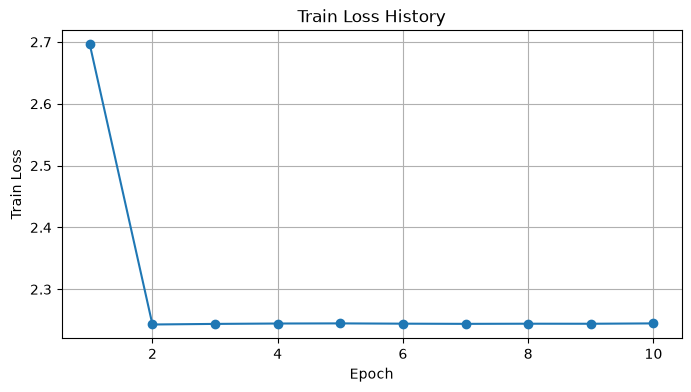

In [10]:
from multiclass_functions import Train

criterion=nn.CrossEntropyLoss()

optimizer=optim.Adam(model.parameters(), lr=LR)

loss_history=Train(model, train_DL, criterion, optimizer, EPOCH)

plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCH+1), loss_history, marker='o')
plt.xlabel('Epoch')
plt.ylabel('Train Loss')
plt.title('Train Loss History')
plt.grid(True)
plt.show()

#### STEP 6. 모델 저장 및 불러오기

**문제**

1. 학습이 끝난 모델의 `state_dict()`를 `results` 폴더에 저장하시오.
2. 동일한 CNN 구조를 새로 생성하시오.
3. 저장한 가중치를 `torch.load(..., map_location=DEVICE)`로 불러오시오.
4. 새 모델에 `load_state_dict()`를 적용하시오.
5. 불러온 모델을 `DEVICE`로 이동하고 `eval()` 모드로 전환하시오.

저장 파일명 예시: `CNN_SVHN.pt`

In [15]:
os.makedirs('results', exist_ok=True)
save_path='results/CNN_SVHN.pt'

torch.save(model.state_dict(), save_path)
load_model=CNN()

state_dict=torch.load(save_path, map_location=DEVICE)

load_model.load_state_dict(state_dict)
load_model=load_model.to(DEVICE)
load_model.eval()

CNN(
  (conv1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (gap): AdaptiveAvgPool2d(output_size=(1, 1))
  (fc): Linear(in_features=128, out_features=10, bias=True)
)

#### STEP 7. 모델 테스트하기

**문제**

1. 불러온 모델을 이용하여 테스트 데이터의 예측값을 계산하시오.
2. `torch.no_grad()`를 이용하여 추론하시오.
3. `argmax(dim=1)`로 예측 클래스를 구하시오.
4. `multiclass_functions.py`의 `Test()` 함수를 이용하여 테스트 정확도를 계산하시오.
5. 정답 개수와 전체 테스트 데이터 개수를 출력하시오.

In [16]:
from multiclass_functions import Test

test_acc=Test(load_model, test_DL)

Test accuracy : 5099 / 26032 (19.6 %)


#### STEP 8. 테스트 결과 시각화

**문제**

1. 테스트 이미지 6장을 시각화하시오.
2. 각 이미지의 실제 정답과 예측 결과를 표시하시오.
3. 정답과 예측이 다르면 제목을 빨간색으로 표시하시오.

**주의:** SVHN은 기본적으로 `classes` 속성을 제공하지 않으므로 숫자 클래스 이름 목록을 사용하시오.

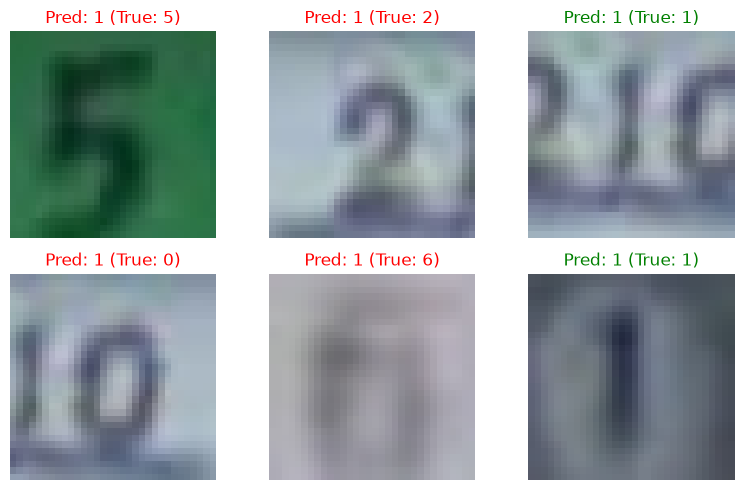

In [17]:
classes=[str(i) for i in range(10)]

load_model.eval()
with torch.no_grad():
    x_batch, y_batch=next(iter(test_DL))
    x_batch = x_batch.to(DEVICE)
    y_hat=load_model(x_batch)
    pred=y_hat.argmax(dim=1).cpu()

x_batch=x_batch.cpu()

plt.figure(figsize=(8, 5))
for idx in range(6):
    plt.subplot(2, 3, idx+1)
    plt.imshow(x_batch[idx].permute(1, 2, 0))
    pred_class=classes[pred[idx].item()]
    true_class=classes[y_batch[idx].item()]
    color='g' if pred_class==true_class else 'r'
    plt.title(f'Pred: {pred_class} (True: {true_class})', color=color)
    plt.axis('off')
plt.tight_layout()
plt.show()

#### STEP 9. 혼동행렬 및 오분류 이미지 분석

**문제 1. Confusion Matrix**

1. `plot_confusion_matrix()` 함수를 이용하여 혼동행렬을 시각화하시오.
2. 행(Row)은 실제 클래스, 열(Column)은 예측 클래스로 표시하시오.
3. 숫자별 정답 개수와 오분류 개수를 확인하시오.

**문제 2. 오분류 이미지 확인**

1. 테스트 데이터에서 실제 정답과 예측값이 다른 인덱스를 찾으시오.
2. 오분류 이미지 중 최대 9장을 시각화하시오.
3. 이미지 위에 실제 정답과 예측값을 표시하시오.
4. 오분류 이미지가 없으면 '오분류 이미지가 없습니다'를 출력하시오.

문제 1


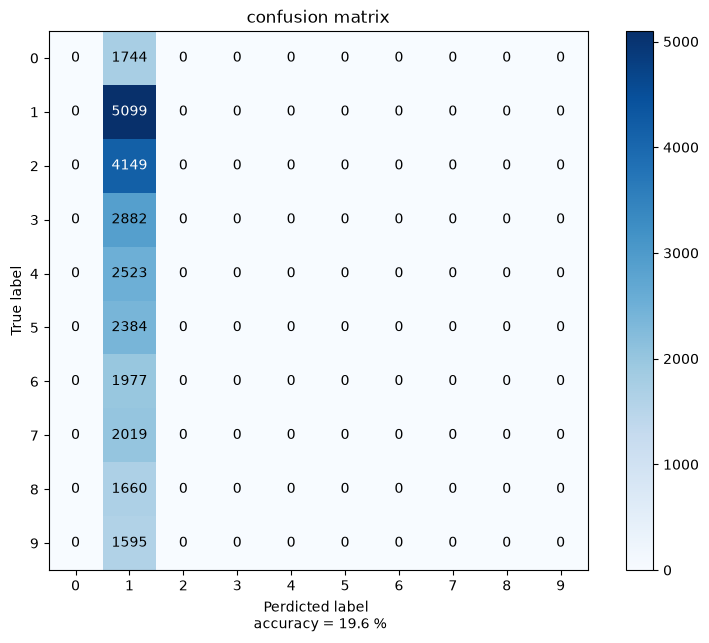

숫자 0 -> 정답: 0개, 오분류: 1744개
숫자 1 -> 정답: 5099개, 오분류: 0개
숫자 2 -> 정답: 0개, 오분류: 4149개
숫자 3 -> 정답: 0개, 오분류: 2882개
숫자 4 -> 정답: 0개, 오분류: 2523개
숫자 5 -> 정답: 0개, 오분류: 2384개
숫자 6 -> 정답: 0개, 오분류: 1977개
숫자 7 -> 정답: 0개, 오분류: 2019개
숫자 8 -> 정답: 0개, 오분류: 1660개
숫자 9 -> 정답: 0개, 오분류: 1595개


In [19]:
print('문제 1')
from multiclass_functions import plot_confusion_matrix

N=len(classes)
confusion=torch.zeros(N, N, dtype=torch.int64)

load_model.eval()
with torch.no_grad():
    for x_batch, y_batch in test_DL:
        x_batch=x_batch.to(DEVICE)
        y_hat=load_model(x_batch)
        pred=y_hat.argmax(dim=1).cpu()
        confusion+=torch.bincount(N * y_batch + pred, minlength=N**2).reshape(N, N)

confusion=confusion.numpy()

plot_confusion_matrix(confusion, classes=classes)
plt.show()

for i in range(N):
    correct=confusion[i, i]
    wrong=confusion[i].sum() - correct
    print(f'숫자 {classes[i]} -> 정답: {correct}개, 오분류: {wrong}개')

문제 2


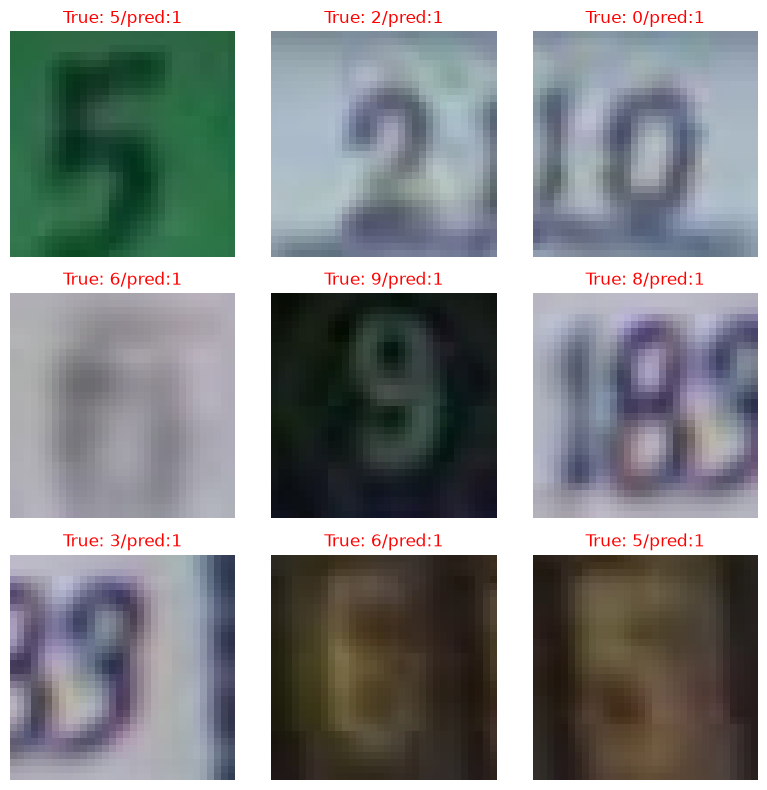

In [22]:
print('문제 2')

wrong_images=[]
wrong_preds=[]
wrong_trues=[]

load_model.eval()
with torch.no_grad():
    for x_batch, y_batch in test_DL:
        x_batch_dev=x_batch.to(DEVICE)
        y_hat=load_model(x_batch_dev)
        pred=y_hat.argmax(dim=1).cpu()

        wrong_idx=torch.where(pred !=y_batch)[0]
        for idx in wrong_idx:
            wrong_images.append(x_batch[idx])
            wrong_preds.append(pred[idx].item())
            wrong_trues.append(y_batch[idx].item())
            if len(wrong_images)==9:
                break
        if len(wrong_images)==9:
            break

if len(wrong_images)==0:
    print('오분류 이미지가 없습니다')
else:
    plt.figure(figsize=(8, 8))
    for i in range(len(wrong_images)):
        plt.subplot(3, 3, i+1)
        plt.imshow(wrong_images[i].permute(1, 2, 0))
        plt.title(f'True: {classes[wrong_trues[i]]}/pred:{classes[wrong_preds[i]]}', color='r')
        plt.axis('off')
    plt.tight_layout()
    plt.show()

#### STEP 10. 파라미터 개수 확인

**문제**

1. 학습 가능한 전체 파라미터 개수를 출력하시오.
2. Conv2d와 Linear 계층의 파라미터 개수를 각각 확인하시오.
3. CNN 모델의 학습 가능한 파라미터가 어느 계층에 많이 분포하는지 확인하시오.

In [23]:
total_params=sum(p.numel() for p in load_model.parameters() if p.requires_grad)
print(f'학습 가능한 파라미터 개수: {total_params:,}개\n')

conv_params=0
linear_params=0

print('[계층별 파라미터]')
for name, module in load_model.named_modules():
    if isinstance(module, nn.Conv2d):
        num=sum(p.numel() for p in module.parameters() if p.requires_grad)
        conv_params+=num
        print(f'Conv2d ({name}): {num:, }개')

학습 가능한 파라미터 개수: 94,538개

[계층별 파라미터]


ValueError: Cannot specify ',' with '\x20'.